# 03 · Target and leakage audit

**Question:** can a model reach the label through anything other than the conditions at
the scene? Three routes are tested:

1. **Provenance:** does the old target let a model learn *which feed* a record came from?
2. **Text:** does the description already say how bad the traffic impact is?
3. **Post-event fields:** are there fields only known after the incident?

The answers fix the feature whitelist that `src/accidents/features.py` implements and
`tests/test_features.py` enforces.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split

from accidents import clean, config, evaluate, export, features, ingest, plots, split

plots.use_style()
pd.set_option("display.width", 140)

## 1 · Provenance: the old target is a source detector

The original project used every source from March 2022 to March 2023, labelled Severity
3–4 as positive, and turned the description into eight keyword flags. Those flags are
reproduced here exactly as the original code wrote them (non-capturing groups only).

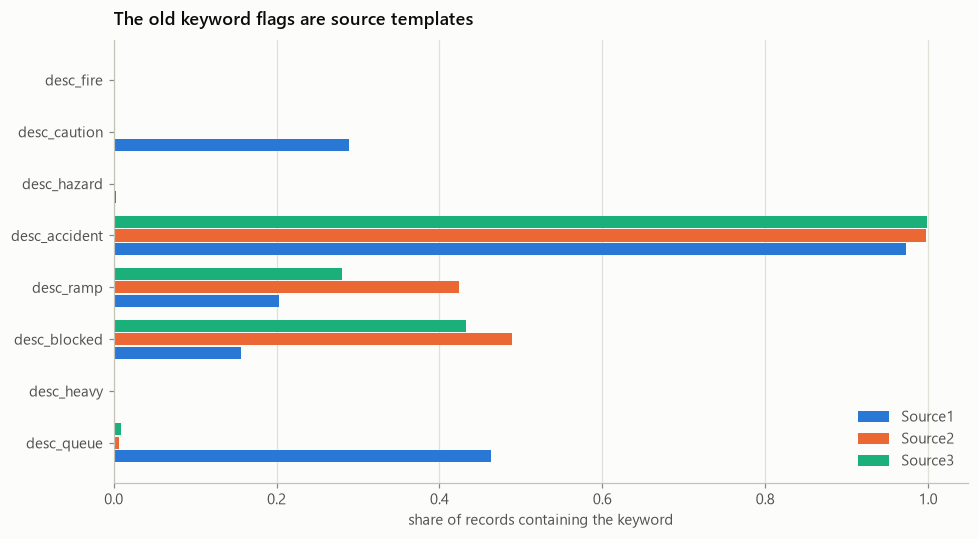

In [2]:
OLD_KEYWORDS = {
    "desc_queue": r"\b(?:queue|backups?|slow|stationary|stop|waiting|delays?)\b",
    "desc_heavy": r"\b(?:heavy|congestion|gridlock|bumper)\b",
    "desc_blocked": r"\b(?:block|close|lane|closed|shut|down)\b",
    "desc_ramp": r"\b(?:ramp|exit|entry|interchange)\b",
    "desc_accident": r"\b(?:accident|crash|collision|incident)\b",
    "desc_hazard": r"\b(?:hazard|debris|object|spill|obstacle|animal)\b",
    "desc_caution": r"\b(?:caution|care|alert|warning)\b",
    "desc_fire": r"\b(?:fire|smoke|flame|burn)\b",
}
old_window = [
    ("Start_Time", ">=", pd.Timestamp("2022-03-01")),
    ("Start_Time", "<", pd.Timestamp("2023-04-01")),
]
old = clean.mask_impossible_readings(
    ingest.read_parquet([*ingest.POPULATION_COLUMNS, "Sunrise_Sunset", "Wind_Chill(F)"], old_window)
).reset_index(drop=True)
text = old["Description"].fillna("").str.lower()
for name, pattern in OLD_KEYWORDS.items():
    old[name] = text.str.contains(pattern, regex=True).astype("int8")
old["old_target"] = (old["Severity"] >= 3).astype("int8")
sources = ["Source1", "Source2", "Source3"]
prevalence = old.groupby("Source")[list(OLD_KEYWORDS)].mean().T[sources]

fig, ax = plt.subplots(figsize=(9, 5))
yy = np.arange(len(prevalence))
height = 0.26
for i, source in enumerate(sources):
    ax.barh(
        yy + (i - 1) * height,
        prevalence[source],
        height=height * 0.9,
        color=plots.SERIES[i],
        label=source,
    )
ax.set_yticks(yy, prevalence.index)
ax.set_xlabel("share of records containing the keyword")
ax.set_title("The old keyword flags are source templates")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [3]:
is_other_source = (old["Source"] != "Source1").astype(int)
x_train, x_test, s_train, s_test = train_test_split(
    old[list(OLD_KEYWORDS)],
    is_other_source,
    test_size=0.2,
    stratify=is_other_source,
    random_state=config.SEED,
)
source_model = LGBMClassifier(n_estimators=200, verbose=-1, random_state=config.SEED)
source_model.fit(x_train, s_train)
source_auc = roc_auc_score(s_test, source_model.predict_proba(x_test)[:, 1])
print(
    f"ROC-AUC for telling Source2/3 from Source1 using only the 8 keyword flags: {source_auc:.3f}"
)

ROC-AUC for telling Source2/3 from Source1 using only the 8 keyword flags: 0.915


### The old model on a random split, and on the months after training

The old configuration (LightGBM, 200 trees, learning rate 0.11, 65 leaves, class weight
1:16, threshold 0.5) on the old feature set, approximated from raw columns. First on a
random 80/20 split, as originally evaluated; then trained on March–September 2022 and
tested on October 2022 – March 2023, when only Source1 was still reporting.

In [4]:
old["hour"] = old["Start_Time"].dt.hour
old["month"] = old["Start_Time"].dt.month
old["is_night"] = (old["Sunrise_Sunset"] == "Night").astype("int8")
old_highway_words = [
    "i-",
    "interstate",
    "hwy",
    "highway",
    "route",
    "st",
    "state",
    "turnpike",
    "fwy",
    "freeway",
    "expy",
    "expressway",
    "pkwy",
    "parkway",
    "us-",
    "u.s.",
    "loop",
    "bypass",
]
street = old["Street"].fillna("").str.lower()
old["old_highway"] = street.apply(lambda s: any(w in s for w in old_highway_words)).astype("int8")
old["weather"] = features.map_unique(old["Weather_Condition"], features.weather_category).astype(
    "category"
)
old["wind_direction"] = old["Wind_Direction"].astype("category")
old_features = [
    *OLD_KEYWORDS,
    "Temperature(F)",
    "Wind_Chill(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    *features.POI_COLUMNS,
    "hour",
    "month",
    "is_night",
    "old_highway",
    "weather",
    "wind_direction",
]


def old_configuration():
    return LGBMClassifier(
        n_estimators=200,
        learning_rate=0.11,
        num_leaves=65,
        class_weight={0: 1, 1: 16},
        random_state=config.SEED,
        verbose=-1,
    )


def summary(y, p):
    flagged = p >= 0.5
    return {
        "average_precision": average_precision_score(y, p),
        "recall@0.5": recall_score(y, flagged),
        "precision@0.5": precision_score(y, flagged),
        "actual positive rate": y.mean(),
    }


x = old[old_features]
y_old = old["old_target"]
x_tr, x_te, y_tr, y_te = train_test_split(
    x, y_old, test_size=0.2, stratify=y_old, random_state=config.SEED
)
random_model = old_configuration().fit(x_tr, y_tr)
p_random = random_model.predict_proba(x_te)[:, 1]

later = old["Start_Time"] >= "2022-10-01"
future_model = old_configuration().fit(x[~later], y_old[~later])
p_future = future_model.predict_proba(x[later])[:, 1]

results = pd.DataFrame(
    {
        "random 80/20 split (as originally reported)": summary(y_te, p_random),
        "trained Mar–Sep 2022, tested Oct 2022–Mar 2023": summary(y_old[later], p_future),
    }
).T
display(results.round(3))
print("sources in the later test months:", old.loc[later, "Source"].value_counts().to_dict())

,average_precision,recall@0.5,precision@0.5,actual positive rate
random 80/20 split (as originally reported),0.500,0.956,0.268,0.059
"trained Mar–Sep 2022, tested Oct 2022–Mar 2023",0.149,0.900,0.137,0.028


sources in the later test months: {'Source1': 651635}


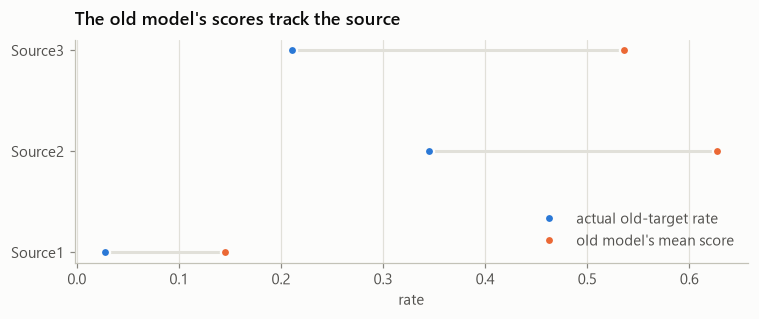

,actual rate,mean predicted probability
Source,,
Source1,0.028,0.145
Source2,0.345,0.627
Source3,0.211,0.536


In [5]:
by_source = pd.DataFrame(
    {
        "actual rate": y_te.groupby(old.loc[y_te.index, "Source"]).mean(),
        "mean predicted probability": pd.Series(p_random, index=y_te.index)
        .groupby(old.loc[y_te.index, "Source"])
        .mean(),
    }
).loc[sources]
fig, ax = plt.subplots(figsize=(7, 3))
yy = np.arange(len(by_source))
ax.hlines(
    yy,
    by_source["actual rate"],
    by_source["mean predicted probability"],
    color=plots.GRID,
    linewidth=2,
)
ax.plot(
    by_source["actual rate"],
    yy,
    "o",
    color=plots.SERIES[0],
    label="actual old-target rate",
    markeredgecolor=plots.SURFACE,
    markeredgewidth=1.5,
)
ax.plot(
    by_source["mean predicted probability"],
    yy,
    "o",
    color=plots.SERIES[1],
    label="old model's mean score",
    markeredgecolor=plots.SURFACE,
    markeredgewidth=1.5,
)
ax.set_yticks(yy, by_source.index)
ax.set_xlabel("rate")
ax.set_title("The old model's scores track the source")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
display(by_source.round(3))
del old, x, x_tr, x_te, text  # free the all-source window before the population sections

## 2 · Text: the description nearly states the label

Inside the target population (Source1, stable regime), a bag-of-words model is trained on
the description alone (TF-IDF of words and word pairs, logistic regression) using a
600k-row sample of training months, and scored on the validation months.

fitted in 26 s on 42,876 terms


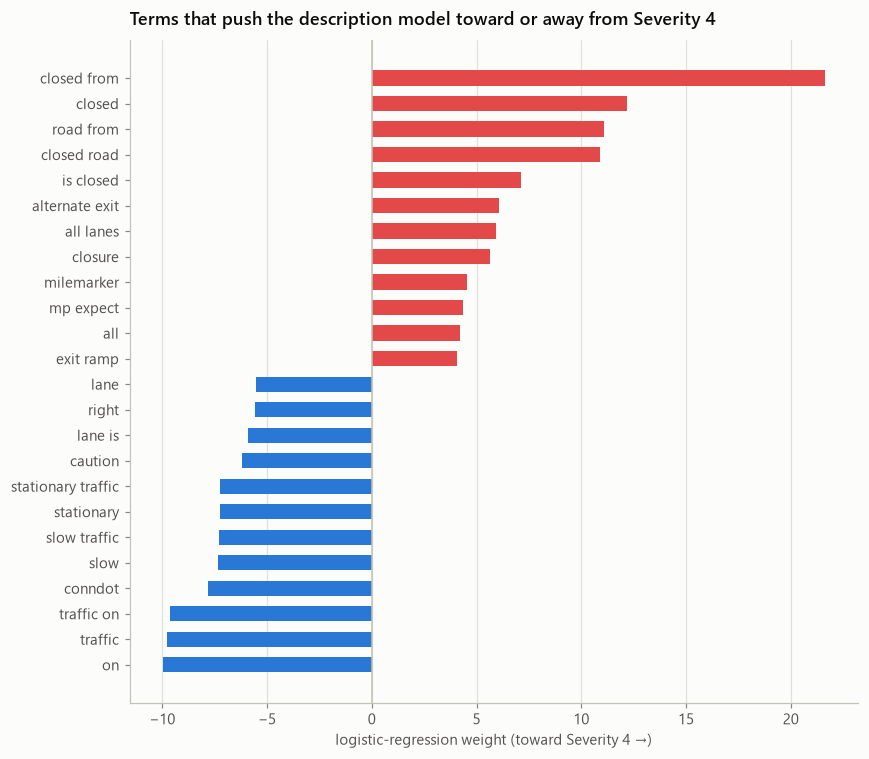

In [6]:
population = clean.mask_impossible_readings(
    clean.target_window(ingest.read_parquet(ingest.POPULATION_COLUMNS, ingest.POPULATION_ROWS))
)
population["split"] = split.assign_split(population["Start_Time"])
train_rows = population[population["split"] == "train"].sample(600_000, random_state=config.SEED)
valid_rows = population[population["split"] == "valid"]

started = time.perf_counter()
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), min_df=20, max_features=200_000, sublinear_tf=True, dtype=np.float32
)
text_train = vectorizer.fit_transform(train_rows["Description"].fillna(""))
text_valid = vectorizer.transform(valid_rows["Description"].fillna(""))
text_model = LogisticRegression(C=1.0, max_iter=1000, solver="liblinear")
text_model.fit(text_train, train_rows["y"])
p_text = text_model.predict_proba(text_valid)[:, 1]
print(f"fitted in {time.perf_counter() - started:.0f} s on {text_train.shape[1]:,} terms")

coef = pd.Series(text_model.coef_[0], index=vectorizer.get_feature_names_out())
top = pd.concat([coef.nsmallest(12), coef.nlargest(12)]).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(
    top.index,
    top.values,
    height=0.6,
    color=[plots.RED_ARM if v > 0 else plots.BLUE_ARM for v in top.values],
)
ax.axvline(0, color=plots.BASELINE, linewidth=1)
ax.set_xlabel("logistic-regression weight (toward Severity 4 →)")
ax.set_title("Terms that push the description model toward or away from Severity 4")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Conditions only vs conditions plus text

The same gradient-boosting setup on the whitelisted condition features (built by
`features.build_model_table`), with and without the eight keyword flags, against the
description-only model. Average precision on the validation months with 95% day-block
bootstrap intervals; the base rate is what a model with no information scores.

,average_precision,low,high,roc_auc
conditions only,0.191,0.185,0.199,0.858
conditions + keyword flags,0.289,0.281,0.297,0.959
description text only,0.481,0.471,0.492,0.979


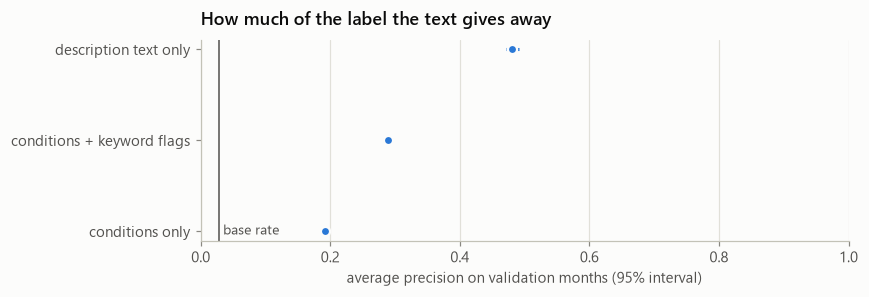

In [7]:
prior = population.loc[population["split"] == "train", "y"].mean()
table = features.build_model_table(population.drop(columns=["split"]), prior)
table["split"] = split.assign_split(table["start_time"])
text_flags = population["Description"].fillna("").str.lower()
for name, pattern in OLD_KEYWORDS.items():
    table[name] = text_flags.str.contains(pattern, regex=True).astype("int8").to_numpy()

fit_rows = table[table["split"] == "train"]
eval_rows = table[table["split"] == "valid"]
scored = {}
for label, columns in [
    ("conditions only", features.FEATURES),
    ("conditions + keyword flags", features.FEATURES + list(OLD_KEYWORDS)),
]:
    model = LGBMClassifier(
        n_estimators=400, learning_rate=0.05, num_leaves=63, random_state=config.SEED, verbose=-1
    )
    model.fit(fit_rows[columns], fit_rows["y"])
    scored[label] = model.predict_proba(eval_rows[columns])[:, 1]
scored["description text only"] = p_text  # same validation rows, same order

y_valid = eval_rows["y"].to_numpy()
days = eval_rows["start_time"].dt.normalize().to_numpy()
samples = evaluate.bootstrap(y_valid, scored, days, n_boot=300)
comparison = pd.DataFrame(
    {
        "average_precision": {k: average_precision_score(y_valid, p) for k, p in scored.items()},
        "low": {k: evaluate.interval(samples[k])[0] for k in scored},
        "high": {k: evaluate.interval(samples[k])[1] for k in scored},
        "roc_auc": {k: roc_auc_score(y_valid, p) for k, p in scored.items()},
    }
).sort_values("average_precision")
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(8, 2.8))
yy = np.arange(len(comparison))
ax.hlines(yy, comparison["low"], comparison["high"], color=plots.SERIES[0], linewidth=2)
ax.plot(
    comparison["average_precision"],
    yy,
    "o",
    color=plots.SERIES[0],
    markeredgecolor=plots.SURFACE,
    markeredgewidth=1.5,
)
ax.axvline(y_valid.mean(), color=plots.INK_SECONDARY, linewidth=1)
ax.text(
    y_valid.mean(),
    0.03,
    " base rate",
    transform=ax.get_xaxis_transform(),
    color=plots.INK_SECONDARY,
    fontsize=9,
)
ax.set_yticks(yy, comparison.index)
ax.set_xlim(0, 1)
ax.set_xlabel("average precision on validation months (95% interval)")
ax.set_title("How much of the label the text gives away")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3 · Post-event fields

`End_Time` is when the incident cleared and `Distance(mi)` is the length of road it
affected; both are recorded after the fact. Here is how each relates to the label.

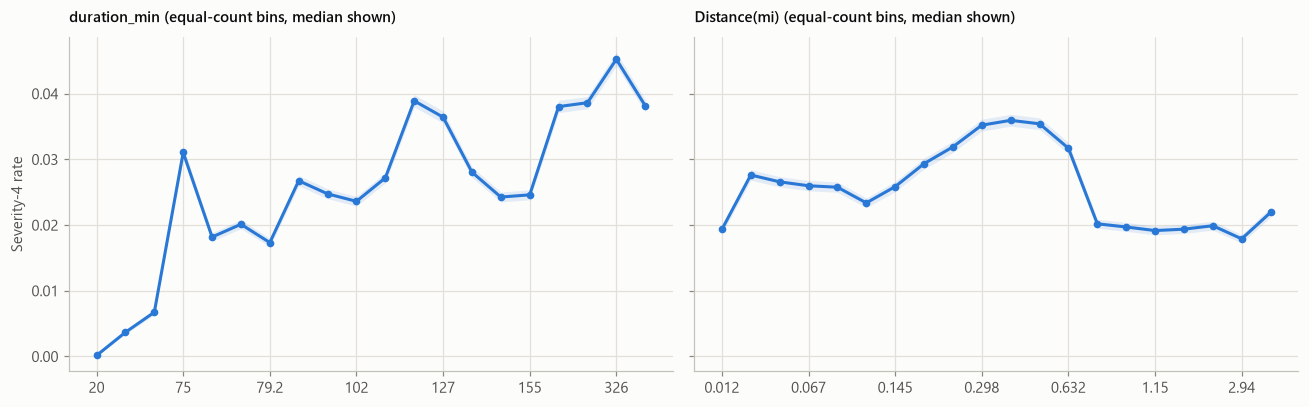

average precision of each field alone on validation months (best direction): {'duration_min': 0.045, 'Distance(mi)': 0.032}


In [8]:
population["duration_min"] = (
    population["End_Time"] - population["Start_Time"]
).dt.total_seconds() / 60
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
post_event = {}
for ax, column in zip(axes, ["duration_min", "Distance(mi)"], strict=True):
    values = population[column]
    bins = pd.qcut(values, 20, duplicates="drop")
    rates = evaluate.rate_table(population["y"], bins)
    centres = population.groupby(bins, observed=True)[column].median()
    ax.fill_between(
        np.arange(len(rates)),
        rates["low"],
        rates["high"],
        color=plots.SERIES[0],
        alpha=0.12,
        linewidth=0,
    )
    ax.plot(np.arange(len(rates)), rates["rate"], color=plots.SERIES[0], marker="o", markersize=4)
    ax.set_xticks(np.arange(len(rates))[::3], [f"{c:.3g}" for c in centres.iloc[::3]])
    ax.set_title(f"{column} (equal-count bins, median shown)", fontsize=10)
    valid_mask = population["split"] == "valid"
    v = values[valid_mask].fillna(values.median())
    post_event[column] = max(
        average_precision_score(population.loc[valid_mask, "y"], v),
        average_precision_score(population.loc[valid_mask, "y"], -v),
    )
axes[0].set_ylabel("Severity-4 rate")
plt.tight_layout()
plt.show()
print(
    "average precision of each field alone on validation months (best direction):",
    {k: round(v, 3) for k, v in post_event.items()},
)

## 4 · The feature whitelist

Every raw column and what happens to it. The headline model uses only fields known when an
accident is first reported and that a dashboard user can enter.

In [9]:
whitelist = pd.DataFrame(
    [
        ("Start_Lat, Start_Lng", "lat, lng; grid-cell history", "used", "place; known at report"),
        ("State", "state", "used", "place; carries reporting practice (notebook 02)"),
        ("Start_Time", "hour, weekday, month, weekend, holiday", "used", "local time of report"),
        ("Weather readings (6)", "same, missing kept", "used", "nearest station at report"),
        ("Weather_Condition", "weather (7 classes)", "used", "ordered rules, all 107 values"),
        ("Wind_Direction", "wind_direction", "used", "18 values + unknown"),
        ("Street", "road_class (5 classes)", "used", "strict rules; replaces Is_Highway"),
        ("12 roadside flags", "same", "used", "map attributes, static"),
        ("Description", "—", "excluded", "near-tautological with the label (section 2)"),
        ("Source", "—", "excluded", "population restricted to Source1 (section 1)"),
        ("End_Time, End_Lat, End_Lng", "—", "excluded", "only known after clearance"),
        ("Distance(mi)", "—", "excluded", "affected length, measured afterwards"),
        ("Wind_Chill(F)", "—", "excluded", "derived from temperature and wind"),
        ("Sunrise_Sunset, twilights", "—", "excluded", "duplicates hour × place"),
        ("Turning_Loop", "—", "excluded", "always false"),
        ("City, County, Zipcode, Airport_Code", "—", "excluded", "covered by location features"),
        ("Weather_Timestamp, ID, Country, Timezone", "—", "excluded", "no predictive role"),
    ],
    columns=["raw column", "model feature", "status", "reason"],
)
display(whitelist)
print(f"{len(features.FEATURES)} model features:", features.FEATURES)

,raw column,model feature,status,reason
0,"Start_Lat, Start_Lng","lat, lng; grid-cell history",used,place; known at report
1,State,state,used,place; carries reporting practice (notebook 02)
2,Start_Time,"hour, weekday, month, weekend, holiday",used,local time of report
3,Weather readings (6),"same, missing kept",used,nearest station at report
4,Weather_Condition,weather (7 classes),used,"ordered rules, all 107 values"
5,Wind_Direction,wind_direction,used,18 values + unknown
6,Street,road_class (5 classes),used,strict rules; replaces Is_Highway
7,12 roadside flags,same,used,"map attributes, static"
8,Description,—,excluded,near-tautological with the label (section 2)
9,Source,—,excluded,population restricted to Source1 (section 1)


31 model features: ['lat', 'lng', 'temperature_f', 'humidity_pct', 'pressure_in', 'visibility_mi', 'wind_speed_mph', 'precipitation_in', 'hour', 'weekday', 'month', 'is_weekend', 'is_holiday', 'cell_count', 'cell_rate', 'amenity', 'bump', 'crossing', 'give_way', 'junction', 'no_exit', 'railway', 'roundabout', 'station', 'stop', 'traffic_calming', 'traffic_signal', 'state', 'road_class', 'weather', 'wind_direction']


## Saved for the dashboard

In [10]:
STORY = config.ROOT / "data" / "processed" / "story"
STORY.mkdir(parents=True, exist_ok=True)
leakage = {
    "source_auc_from_keywords": float(source_auc),
    "keyword_prevalence_by_source": export.records(prevalence),
    "old_model": export.records(results.rename_axis("evaluation")),
    "old_model_by_source": export.records(by_source),
    "text_audit": export.records(comparison.rename_axis("model")),
    "top_terms": top.round(4).to_dict(),
    "post_event_ap": {k: float(v) for k, v in post_event.items()},
}
(STORY / "leakage.json").write_text(json.dumps(leakage, indent=2))
print("saved", STORY / "leakage.json")

saved data\processed\story\leakage.json


## Decisions and evidence

**1 · The old target was mostly a source detector.** The eight keyword flags alone tell
Source2/3 from Source1 with ROC-AUC 0.915: "queue"-type words appear in 46% of Source1
descriptions and almost never elsewhere, "blocked"/"ramp" the other way round. The old
configuration reproduces its reported result on a random split (recall 0.956, precision
0.268, AP 0.500). Trained on March–September 2022 and tested on October 2022 – March 2023,
when only Source1 reports, its AP falls to 0.149 and precision to 0.137. On the random split
its mean score per source follows each source's label rate (Source1 0.145 vs actual 0.028;
Source2 0.627 vs 0.345): it learned the feeds, not the roads. → Confirms D4.

**2 · The description nearly states the label.** Within the target population, a
description-only bag-of-words model reaches AP 0.481 (ROC-AUC 0.979) on the validation
months, against a base rate of about 0.03. Its strongest terms are closure language
("closed from", "closed", "closed road", "closure", "all lanes"). Its strongest negative terms
are queue language ("slow traffic", "stationary traffic"). A road closure *is* a major traffic
impact, so the text reports the outcome rather than predicting it. Adding just the eight
keyword flags lifts the conditions model from AP 0.191 to 0.289.
→ **D6:** no description text in the headline model. The audit model is kept here as
evidence and is never deployed.

**3 · Post-event fields are weak alone, and excluded anyway.** Clearance duration
(AP 0.045 alone) and affected distance (0.032) relate to the label only modestly, but neither
exists when an accident is first reported, so neither may be used.

**4 · The honest baseline.** Conditions only (place, time, weather, road, 31 features)
already reach AP 0.191 [0.185, 0.199] and ROC-AUC 0.858 on validation months, about six
times the base rate. That is the number notebook 05 has to improve on with tuned models.

**Whitelist:** the 31 features printed above, enforced by
`tests/test_features.py::test_feature_whitelist_has_no_banned_or_raw_names`.